** Meningitis Missingness Dataset**
- perform data cleaning, feature engineering, transformations and feature engineering as required by the data 
- perform hypothesis testing and exploratory data analysis 
- classification 
- What model can predict most accurately whether a pathogen is present 
- What model can predict the outcome most accurately 

<p>What can I use agentic AI for with this problem statement</p>
- The agent’s purpose is to explain, in plain language, why a meningitis case was classified as High, Moderate, or Low Risk, so that people without a data science background can understand and question the model’s predictions.

It works in three layers:

Prediction. A random forest model predicts each patient’s risk level from spinal fluid labs (CRP, glucose, protein, white cell count), blood labs, age, gender, pathogen detection, and diagnosis.
Attribution. SHAP values measure how much each factor pushed a specific patient’s prediction toward or away from their predicted risk level.
Explanation. A Claude agent calls these results as tools and turns them into a short, readable answer. For example: “This patient is predicted High Risk with high confidence, mainly because their spinal fluid glucose was much lower than most patients’ and the diagnosis was bacterial.”

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
meningitis_dirty = pd.read_csv("mening_missing.csv")
meningitis_dirty.head(5)

,Patient_ID,Age,Gender,WBC_Count,Protein_Level,Glucose_Level,Pathogen_Present,Diagnosis,Outcome,Hemoglobin,WBC_Blood_Count,Platelets,CRP_Level,Risk_Level
0,1,101.0,Female,8624.0,16.0,83.0,No,Viral,Recovered,15.0,7269.0,160949.0,71.0,Moderate Risk
1,2,78.0,Male,22623.0,200.0,41.0,No,Unknown,Recovered,18.0,6532.0,371741.0,41.0,High Risk
2,3,8.0,Female,12908.0,39.0,3.0,No,Unknown,Recovered,16.0,7417.0,180403.0,22.0,Moderate Risk
3,4,104.0,Female,15072.0,58.0,36.0,Yes,Bacterial,Recovered,7.0,13792.0,132254.0,48.0,Moderate Risk
4,5,38.0,Female,18623.0,152.0,34.0,Yes,Bacterial,Recovered,5.0,17054.0,134941.0,28.0,High Risk


In [3]:
meningitis_clean = meningitis_dirty.copy()

In [4]:
meningitis_clean.dtypes

Patient_ID            int64
Age                 float64
Gender                  str
WBC_Count           float64
Protein_Level       float64
Glucose_Level       float64
Pathogen_Present        str
Diagnosis               str
Outcome                 str
Hemoglobin          float64
WBC_Blood_Count     float64
Platelets           float64
CRP_Level           float64
Risk_Level              str
dtype: object

**Step 1: Data Cleaning**

In [5]:
#drop patient ID column
meningitis_clean = meningitis_clean.drop(columns=["Patient_ID"])
meningitis_clean

,Age,Gender,WBC_Count,Protein_Level,Glucose_Level,Pathogen_Present,Diagnosis,Outcome,Hemoglobin,WBC_Blood_Count,Platelets,CRP_Level,Risk_Level
0,101.0,Female,8624.0,16.0,83.0,No,Viral,Recovered,15.0,7269.0,160949.0,71.0,Moderate Risk
1,78.0,Male,22623.0,200.0,41.0,No,Unknown,Recovered,18.0,6532.0,371741.0,41.0,High Risk
2,8.0,Female,12908.0,39.0,3.0,No,Unknown,Recovered,16.0,7417.0,180403.0,22.0,Moderate Risk
3,104.0,Female,15072.0,58.0,36.0,Yes,Bacterial,Recovered,7.0,13792.0,132254.0,48.0,Moderate Risk
4,38.0,Female,18623.0,152.0,34.0,Yes,Bacterial,Recovered,5.0,17054.0,134941.0,28.0,High Risk
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1195,64.0,Male,13772.0,163.0,118.0,No,Unknown,Recovered,16.0,9267.0,183229.0,29.0,Low Risk
1196,79.0,Male,17393.0,117.0,2.0,No,Unknown,Recovered,18.0,6952.0,291451.0,23.0,Low Risk
1197,25.0,Female,8005.0,23.0,69.0,No,Viral,Recovered,13.0,7389.0,275364.0,4.0,Low Risk
1198,73.0,Male,13581.0,161.0,29.0,Yes,Bacterial,Recovered,7.0,19034.0,102130.0,35.0,High Risk


In [6]:
meningitis_clean.head(5)

,Age,Gender,WBC_Count,Protein_Level,Glucose_Level,Pathogen_Present,Diagnosis,Outcome,Hemoglobin,WBC_Blood_Count,Platelets,CRP_Level,Risk_Level
0,101.0,Female,8624.0,16.0,83.0,No,Viral,Recovered,15.0,7269.0,160949.0,71.0,Moderate Risk
1,78.0,Male,22623.0,200.0,41.0,No,Unknown,Recovered,18.0,6532.0,371741.0,41.0,High Risk
2,8.0,Female,12908.0,39.0,3.0,No,Unknown,Recovered,16.0,7417.0,180403.0,22.0,Moderate Risk
3,104.0,Female,15072.0,58.0,36.0,Yes,Bacterial,Recovered,7.0,13792.0,132254.0,48.0,Moderate Risk
4,38.0,Female,18623.0,152.0,34.0,Yes,Bacterial,Recovered,5.0,17054.0,134941.0,28.0,High Risk


**Check for Missingness in Categorical Columns**
- Fill unknown gender values as Unknown
- Drop records in pathogen_present and outcome_df instead of imputting them 

In [7]:
categorical_columns = ["Gender", "Pathogen_Present", "Outcome"]
meningitis_clean[categorical_columns].isna().sum()

Gender               9
Pathogen_Present     8
Outcome             10
dtype: int64

In [8]:
meningitis_clean["Gender"] = meningitis_clean["Gender"].fillna("Unknown")
meningitis_clean["Diagnosis"] = meningitis_clean["Diagnosis"].fillna("Unknown")

In [9]:
meningitis_clean.head(5)

,Age,Gender,WBC_Count,Protein_Level,Glucose_Level,Pathogen_Present,Diagnosis,Outcome,Hemoglobin,WBC_Blood_Count,Platelets,CRP_Level,Risk_Level
0,101.0,Female,8624.0,16.0,83.0,No,Viral,Recovered,15.0,7269.0,160949.0,71.0,Moderate Risk
1,78.0,Male,22623.0,200.0,41.0,No,Unknown,Recovered,18.0,6532.0,371741.0,41.0,High Risk
2,8.0,Female,12908.0,39.0,3.0,No,Unknown,Recovered,16.0,7417.0,180403.0,22.0,Moderate Risk
3,104.0,Female,15072.0,58.0,36.0,Yes,Bacterial,Recovered,7.0,13792.0,132254.0,48.0,Moderate Risk
4,38.0,Female,18623.0,152.0,34.0,Yes,Bacterial,Recovered,5.0,17054.0,134941.0,28.0,High Risk


**Check for Missingness in Numeric Columns**

In [10]:
numeric_columns = ["Age", "WBC_Count", "Protein_Level", "Glucose_Level", "Hemoglobin", "WBC_Blood_Count", "Platelets", "CRP_Level"]

meningitis_clean[numeric_columns].isna().sum()

Age                 7
WBC_Count           8
Protein_Level      10
Glucose_Level       8
Hemoglobin         19
WBC_Blood_Count    10
Platelets          12
CRP_Level          13
dtype: int64

**Work with Cleaning up the BS in the Numeric data**
- set all values with age over 110 years old to np.nan
- Set all values with protein level of 0 to np.nan (impossible)
- Set all values with Glucode level fo 0 to np.nan (impossible)

In [11]:
meningitis_clean.loc[meningitis_clean["Age"] > 110, "Age"] = np.nan

In [12]:
meningitis_clean.head(5)

,Age,Gender,WBC_Count,Protein_Level,Glucose_Level,Pathogen_Present,Diagnosis,Outcome,Hemoglobin,WBC_Blood_Count,Platelets,CRP_Level,Risk_Level
0,101.0,Female,8624.0,16.0,83.0,No,Viral,Recovered,15.0,7269.0,160949.0,71.0,Moderate Risk
1,78.0,Male,22623.0,200.0,41.0,No,Unknown,Recovered,18.0,6532.0,371741.0,41.0,High Risk
2,8.0,Female,12908.0,39.0,3.0,No,Unknown,Recovered,16.0,7417.0,180403.0,22.0,Moderate Risk
3,104.0,Female,15072.0,58.0,36.0,Yes,Bacterial,Recovered,7.0,13792.0,132254.0,48.0,Moderate Risk
4,38.0,Female,18623.0,152.0,34.0,Yes,Bacterial,Recovered,5.0,17054.0,134941.0,28.0,High Risk


In [13]:
# CSF protein can't be 0: some protein always crosses the blood-brain barrier
meningitis_clean.loc[meningitis_clean["Protein_Level"] == 0, "Protein_Level"] = np.nan

# CSF glucose of 0 can mean "undetectable" in severe bacterial meningitis, so keep
# those zeros, except where the diagnosis is viral (glucose is usually normal there)
viral_zero = (meningitis_clean["Glucose_Level"] == 0) & (meningitis_clean["Diagnosis"] == "Viral")
meningitis_clean.loc[viral_zero, "Glucose_Level"] = np.nan

In [14]:
meningitis_clean[numeric_columns].isna().sum()

Age                34
WBC_Count           8
Protein_Level      11
Glucose_Level       9
Hemoglobin         19
WBC_Blood_Count    10
Platelets          12
CRP_Level          13
dtype: int64

**Create New Column CRP_Below_Detection**
- True if CRP is exactly 0 
- False if CRP is not 0

In [15]:
meningitis_clean["CRP_Level_Below_Detection"] = np.where(meningitis_clean["CRP_Level"] == 0, True, False).astype(bool)
meningitis_clean["CRP_Level_Below_Detection"].value_counts()

CRP_Level_Below_Detection
False    1125
True       75
Name: count, dtype: int64

**Assess Why Missingness is occuring in Each Column**

In [16]:
meningitis_clean.head(5)

,Age,Gender,WBC_Count,Protein_Level,Glucose_Level,Pathogen_Present,Diagnosis,Outcome,Hemoglobin,WBC_Blood_Count,Platelets,CRP_Level,Risk_Level,CRP_Level_Below_Detection
0,101.0,Female,8624.0,16.0,83.0,No,Viral,Recovered,15.0,7269.0,160949.0,71.0,Moderate Risk,False
1,78.0,Male,22623.0,200.0,41.0,No,Unknown,Recovered,18.0,6532.0,371741.0,41.0,High Risk,False
2,8.0,Female,12908.0,39.0,3.0,No,Unknown,Recovered,16.0,7417.0,180403.0,22.0,Moderate Risk,False
3,104.0,Female,15072.0,58.0,36.0,Yes,Bacterial,Recovered,7.0,13792.0,132254.0,48.0,Moderate Risk,False
4,38.0,Female,18623.0,152.0,34.0,Yes,Bacterial,Recovered,5.0,17054.0,134941.0,28.0,High Risk,False


In [17]:
categorical_columns = ["Gender", "Pathogen_Present", "Diagnosis", "Outcome", "Risk_Level"]

summary = pd.DataFrame({
    "n_missing": meningitis_clean[categorical_columns].isna().sum(),
    "pct_missing": (meningitis_clean[categorical_columns].isna().mean() * 100).round(2),
})
print(summary)

# Confirm there are no hidden placeholders such as "", " ", "NA", or "?"
for col in categorical_columns:
    print(col, meningitis_clean[col].value_counts(dropna=False).to_dict())

                  n_missing  pct_missing
Gender                    0         0.00
Pathogen_Present          8         0.67
Diagnosis                 0         0.00
Outcome                  10         0.83
Risk_Level                0         0.00
Gender {'Male': 604, 'Female': 587, 'Unknown': 9}
Pathogen_Present {'No': 620, 'Yes': 572, nan: 8}
Diagnosis {'Viral': 565, 'Bacterial': 499, 'Unknown': 136}
Outcome {'Recovered': 1069, 'Deceased': 121, nan: 10}
Risk_Level {'Low Risk': 558, 'High Risk': 505, 'Moderate Risk': 137}


In [18]:
from scipy import stats

categorical_columns = ["Gender", "Pathogen_Present", "Diagnosis", "Outcome", "Risk_Level"]
numeric_columns = ["Age", "WBC_Count", "Protein_Level", "Glucose_Level",
                   "Hemoglobin", "WBC_Blood_Count", "Platelets", "CRP_Level"]
df = meningitis_clean

for col in categorical_columns:
    missing = df[col].isna()
    if missing.sum() == 0:
        print(f"{col}: no missing values\n")
        continue

    rows = df.index[missing]
    print(f"{col}: {missing.sum()} missing, rows {rows.min()}-{rows.max()}")
    print("  consecutive block:", (rows.max() - rows.min() + 1) == len(rows))

    results = []
    # Numeric variables: Mann-Whitney U (missing vs. not missing)
    for other in numeric_columns:
        a = df.loc[missing, other].dropna()
        b = df.loc[~missing, other].dropna()
        p = stats.mannwhitneyu(a, b).pvalue
        results.append({"variable": other, "test": "Mann-Whitney", "p_value": p})
    # Categorical variables: chi-square on missing vs. category
    for other in categorical_columns:
        if other == col:
            continue
        table = pd.crosstab(missing, df[other].fillna("Missing"))
        p = stats.chi2_contingency(table)[1]
        results.append({"variable": other, "test": "Chi-square", "p_value": p})

    res = pd.DataFrame(results).sort_values("p_value")
    n_tests = len(res)
    res["p_value"] = res["p_value"].round(3)
    res["sig_.05"] = res["p_value"] < 0.05
    res["sig_bonferroni"] = res["p_value"] < 0.05 / n_tests
    print(res.to_string(index=False))
    print(f"  {res['sig_.05'].sum()} of {n_tests} significant at .05; "
          f"{res['sig_bonferroni'].sum()} after Bonferroni (p < {0.05 / n_tests:.4f})\n")

Gender: no missing values

Pathogen_Present: 8 missing, rows 56-63
  consecutive block: True
       variable         test  p_value  sig_.05  sig_bonferroni
WBC_Blood_Count Mann-Whitney    0.046     True           False
      Platelets Mann-Whitney    0.049     True           False
     Risk_Level   Chi-square    0.060    False           False
      WBC_Count Mann-Whitney    0.173    False           False
            Age Mann-Whitney    0.196    False           False
     Hemoglobin Mann-Whitney    0.325    False           False
  Protein_Level Mann-Whitney    0.346    False           False
      CRP_Level Mann-Whitney    0.370    False           False
      Diagnosis   Chi-square    0.383    False           False
        Outcome   Chi-square    0.611    False           False
         Gender   Chi-square    0.731    False           False
  Glucose_Level Mann-Whitney    0.894    False           False
  2 of 12 significant at .05; 0 after Bonferroni (p < 0.0042)

Diagnosis: no missing val

**Missingness Writeup**

“Missingness in Pathogen_Present (n = 8) and Outcome (n = 10) occurred in single contiguous blocks of records. Missingness indicators were compared against all other variables (Mann-Whitney U for numeric, chi-square for categorical); no association remained significant after Bonferroni correction (α = .0042), consistent with MCAR. As both variables are classification targets (outcome and pathogen_present), records with a missing target were excluded from the corresponding model rather than imputed.”

**Decision Time: What to Do with the Null Values**
<p>Categorical</p> 
- Drop nulls in outcome and pathogen, I plan on using both as target variables for different problems
- never impute target variables 

<p>Numeric</p>
- Apply the column's median value to fill missing values

In [19]:
meningitis_clean = meningitis_clean.dropna(subset=["Pathogen_Present"])
meningitis_clean = meningitis_clean.dropna(subset=["Outcome"])
meningitis_clean[categorical_columns].isna().sum()

Gender              0
Pathogen_Present    0
Diagnosis           0
Outcome             0
Risk_Level          0
dtype: int64

In [20]:
num_cols = ["Age", "Protein_Level", "Glucose_Level", "Hemoglobin",
            "WBC_Count", "WBC_Blood_Count", "Platelets", "CRP_Level"]

# Flag which values were filled, before filling them
meningitis_clean["Age_imputed"] = meningitis_clean["Age"].isna()

medians = meningitis_clean[num_cols].median()
print(medians)  # record these for your write-up

Age                    42.0
Protein_Level         109.0
Glucose_Level          53.0
Hemoglobin             12.0
WBC_Count           12282.0
WBC_Blood_Count      9831.5
Platelets          159797.5
CRP_Level              25.0
dtype: float64


In [21]:
meningitis_clean[num_cols] = meningitis_clean[num_cols].fillna(medians)

In [22]:
meningitis_clean[numeric_columns].isna().sum()

Age                0
WBC_Count          0
Protein_Level      0
Glucose_Level      0
Hemoglobin         0
WBC_Blood_Count    0
Platelets          0
CRP_Level          0
dtype: int64

**Convert Columns from Float to Integer Data Type**
- Age
- CRP_Level
- WBC_Count
- Hemoglobin
- Glucose_Level
- Protein_Level

In [23]:
numeric_columns_int = ["Age","CRP_Level", 
                       "WBC_Count", "Hemoglobin",
                       "Glucose_Level", "Protein_Level"
                      ]

In [24]:
meningitis_clean[numeric_columns_int] = meningitis_clean[numeric_columns_int].round().astype("Int64")

**Create New Column for Age_Group**

In [25]:
def age_group(age):
    if pd.isna(age):
        return pd.NA
    elif age < 1:
        return "Infant (<1)"
    elif age < 5:
        return "Young Child (1-4)"
    elif age < 13:
        return "Child (5-12)"
    elif age < 18:
        return "Adolescent (13-17)"
    elif age < 25:
        return "Young adult (18-24)"
    elif age < 65:
        return "Adult (25-64)"
    else:
        return "Older adult (65+)"

meningitis_clean["Age_Group"] = meningitis_clean["Age"].apply(age_group)
meningitis_clean["Age_Group"].value_counts(dropna=False)

Age_Group
Adult (25-64)          752
Older adult (65+)      234
Young adult (18-24)    144
Child (5-12)            26
Young Child (1-4)       12
Adolescent (13-17)       8
Infant (<1)              6
Name: count, dtype: int64

**Define Is_Minor Column**

In [26]:
meningitis_clean["Is_Minor"] = np.where(meningitis_clean["Age"] < 18, True, False).astype(bool)

In [27]:
meningitis_clean.head(5)

,Age,Gender,WBC_Count,Protein_Level,Glucose_Level,Pathogen_Present,Diagnosis,Outcome,Hemoglobin,WBC_Blood_Count,Platelets,CRP_Level,Risk_Level,CRP_Level_Below_Detection,Age_imputed,Age_Group,Is_Minor
0,101,Female,8624,16,83,No,Viral,Recovered,15,7269.0,160949.0,71,Moderate Risk,False,False,Older adult (65+),False
1,78,Male,22623,200,41,No,Unknown,Recovered,18,6532.0,371741.0,41,High Risk,False,False,Older adult (65+),False
2,8,Female,12908,39,3,No,Unknown,Recovered,16,7417.0,180403.0,22,Moderate Risk,False,False,Child (5-12),True
3,104,Female,15072,58,36,Yes,Bacterial,Recovered,7,13792.0,132254.0,48,Moderate Risk,False,False,Older adult (65+),False
4,38,Female,18623,152,34,Yes,Bacterial,Recovered,5,17054.0,134941.0,28,High Risk,False,False,Adult (25-64),False


**Perform One Hot Encoding to Categorical Columns that Are Not Target Values**
- Gender
- Diagnosis

In [28]:
one_hot_columns = ["Gender", "Diagnosis"]

meningitis_clean = pd.get_dummies(meningitis_clean, columns=one_hot_columns, dtype=bool)

meningitis_clean.head(5)

,Age,WBC_Count,Protein_Level,Glucose_Level,Pathogen_Present,Outcome,Hemoglobin,WBC_Blood_Count,Platelets,CRP_Level,...,CRP_Level_Below_Detection,Age_imputed,Age_Group,Is_Minor,Gender_Female,Gender_Male,Gender_Unknown,Diagnosis_Bacterial,Diagnosis_Unknown,Diagnosis_Viral
0,101,8624,16,83,No,Recovered,15,7269.0,160949.0,71,...,False,False,Older adult (65+),False,True,False,False,False,False,True
1,78,22623,200,41,No,Recovered,18,6532.0,371741.0,41,...,False,False,Older adult (65+),False,False,True,False,False,True,False
2,8,12908,39,3,No,Recovered,16,7417.0,180403.0,22,...,False,False,Child (5-12),True,True,False,False,False,True,False
3,104,15072,58,36,Yes,Recovered,7,13792.0,132254.0,48,...,False,False,Older adult (65+),False,True,False,False,True,False,False
4,38,18623,152,34,Yes,Recovered,5,17054.0,134941.0,28,...,False,False,Adult (25-64),False,True,False,False,True,False,False


**Change Data Type for Pathogen_Present from str to boolean**

In [29]:
meningitis_clean["Pathogen_Present"] = meningitis_clean["Pathogen_Present"].map({"Yes": True, "No": False})
meningitis_clean.head(5)

,Age,WBC_Count,Protein_Level,Glucose_Level,Pathogen_Present,Outcome,Hemoglobin,WBC_Blood_Count,Platelets,CRP_Level,...,CRP_Level_Below_Detection,Age_imputed,Age_Group,Is_Minor,Gender_Female,Gender_Male,Gender_Unknown,Diagnosis_Bacterial,Diagnosis_Unknown,Diagnosis_Viral
0,101,8624,16,83,False,Recovered,15,7269.0,160949.0,71,...,False,False,Older adult (65+),False,True,False,False,False,False,True
1,78,22623,200,41,False,Recovered,18,6532.0,371741.0,41,...,False,False,Older adult (65+),False,False,True,False,False,True,False
2,8,12908,39,3,False,Recovered,16,7417.0,180403.0,22,...,False,False,Child (5-12),True,True,False,False,False,True,False
3,104,15072,58,36,True,Recovered,7,13792.0,132254.0,48,...,False,False,Older adult (65+),False,True,False,False,True,False,False
4,38,18623,152,34,True,Recovered,5,17054.0,134941.0,28,...,False,False,Adult (25-64),False,True,False,False,True,False,False


In [30]:
meningitis_clean.dtypes

Age                            Int64
WBC_Count                      Int64
Protein_Level                  Int64
Glucose_Level                  Int64
Pathogen_Present                bool
Outcome                          str
Hemoglobin                     Int64
WBC_Blood_Count              float64
Platelets                    float64
CRP_Level                      Int64
Risk_Level                       str
CRP_Level_Below_Detection       bool
Age_imputed                     bool
Age_Group                        str
Is_Minor                        bool
Gender_Female                   bool
Gender_Male                     bool
Gender_Unknown                  bool
Diagnosis_Bacterial             bool
Diagnosis_Unknown               bool
Diagnosis_Viral                 bool
dtype: object

In [31]:
meningitis_clean.to_csv("meningitis_cleaned_data.csv", index=False)

**Usage of Agentic AI**
- Use an agent to analyze lab results determining a patients risk level (High, Medium, Low)

In [32]:
import json
 
import numpy as np
import pandas as pd
import shap
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

In [33]:
from dotenv import load_dotenv
load_dotenv()

True

In [34]:
#set up the base configuraiton for the agent 

In [35]:
from risk_explainer_agent import RiskExplainer, RiskExplainerAgent

In [36]:
explainer = RiskExplainer(meningitis_clean)   # trains and evaluates the model
explainer.print_evaluation()

Balanced accuracy (test set): 0.860

               precision    recall  f1-score   support

    High Risk       0.98      0.79      0.87       100
     Low Risk       0.99      0.83      0.90       110
Moderate Risk       0.41      0.96      0.57        27

     accuracy                           0.83       237
    macro avg       0.79      0.86      0.78       237
 weighted avg       0.92      0.83      0.85       237

                     pred: High Risk  pred: Low Risk  pred: Moderate Risk
true: High Risk                   79               0                   21
true: Low Risk                     2              91                   17
true: Moderate Risk                0               1                   26


In [37]:
# No API key needed
print(explainer.template_explanation(explainer.explain_patient(23)))

Patient 23 is predicted Low Risk (high confidence, 86%). The main reasons: CRP (a blood marker of inflammation) (2 mg/L, lower than 84% of patients (median 25)), the diagnosis (bacterial, viral, or unknown) (Viral), spinal fluid protein (51 mg/dL, lower than 66% of patients (median 109)). Pointing the other way: white blood cell count in the spinal fluid (12,282 cells/µL, higher than 50% of patients (median 12,282)).


In [38]:
import anthropic

In [39]:
agent = RiskExplainerAgent(explainer)
print(agent.ask("Why was patient 42 rated Low Risk?"))

The model rated patient 42 as **Low Risk** and was very confident, giving it about a 99% probability. This matches the recorded risk level. The model saw this patient while it was learning, so its confidence may be higher than it would be for a new patient.

These factors mattered most, strongest first:
- **CRP (a blood marker of inflammation):** The value was 0 mg/L, which is very low. Only about 3% of patients are lower, and the typical value is 25. The model associates very low CRP with lower risk.
- **Diagnosis:** The diagnosis was viral. The model associates this with Low Risk, because this dataset's risk levels reflect how severe and how likely bacterial a case looks.
- **Spinal fluid protein:** The value was 59 mg/dL, below the typical value of 109.
- **Spinal fluid glucose (sugar):** The value was 53 mg/dL, which is typical. It added a smaller push toward Low Risk.

No factors pointed the other way. This is a model explanation, not medical advice, and it shows patterns the mode

In [40]:
print(agent.ask("Why was patient 6 rated High Risk?"))

The model rated patient 6 as **High Risk** and was very confident, giving it about a 99% probability. This matches the recorded risk level. The model saw this patient while it was learning, so its confidence may be higher than it would be for a new patient.

These factors mattered most, strongest first:
- **Diagnosis:** The diagnosis was bacterial. This was the strongest influence. In this dataset, risk levels reflect how severe and how likely bacterial a case looks.
- **Spinal fluid glucose (sugar):** The value was 26 mg/dL, which is low. Only about a quarter of patients are lower, and the typical value is 53.
- **CRP (a blood marker of inflammation):** The value was 36 mg/L, which is somewhat high. The typical value is 25.
- **Spinal fluid protein:** The value was 171 mg/dL, which is fairly high. The typical value is 109.

The only factor pointing the other way was gender (male), and its influence was negligible.

This is a model explanation, not medical advice. It shows patterns the

In [41]:
print(agent.ask("What is the breakdown of High Risk patient by their respective risk features?"))

There are **499 patients recorded as High Risk**, out of 1,182 in total. Here is how they break down.

**By diagnosis**

| Diagnosis | High Risk patients |
|---|---|
| Bacterial | 429 |
| Unknown | 40 |
| Viral | 30 |

**By pathogen (germ) detection**

| Pathogen | High Risk patients |
|---|---|
| Detected | 448 |
| Not detected | 51 |

**Typical lab values** (High Risk compared with Low Risk, using median values)

| Measure | High Risk | Low Risk |
|---|---|---|
| CRP (inflammation marker) | 35 mg/L | 3 mg/L |
| Spinal fluid glucose (sugar) | 25 mg/dL | 60 mg/dL |
| Spinal fluid protein | 151 mg/dL | 44 mg/dL |
| White blood cells in spinal fluid | 15,856 cells/µL | 7,386 cells/µL |
| White blood cells in blood | 15,442 cells/µL | 7,370 cells/µL |
| Platelets | 127,850 per µL | 251,001 per µL |
| Age | 51 years | 36 years |

**What the model relies on most for High Risk**, strongest first:
1. Diagnosis
2. Spinal fluid glucose
3. Spinal fluid protein
4. CRP
5. White blood cell count in

In [42]:
print(agent.ask("What is the breakdown of Low Risk patient by their respective risk features?"))

There are **549 patients recorded as Low Risk**, out of 1,182 in total. Here is how they break down.

**By diagnosis**

| Diagnosis | Low Risk patients |
|---|---|
| Viral | 473 |
| Unknown | 40 |
| Bacterial | 36 |

**By pathogen (germ) detection**

| Pathogen | Low Risk patients |
|---|---|
| Not detected | 491 |
| Detected | 58 |

**Typical lab values** (Low Risk compared with High Risk, using median values)

| Measure | Low Risk | High Risk |
|---|---|---|
| CRP (inflammation marker) | 3 mg/L | 35 mg/L |
| Spinal fluid glucose (sugar) | 60 mg/dL | 25 mg/dL |
| Spinal fluid protein | 44 mg/dL | 151 mg/dL |
| White blood cells in spinal fluid | 7,386 cells/µL | 15,856 cells/µL |
| White blood cells in blood | 7,370 cells/µL | 15,442 cells/µL |
| Platelets | 251,001 per µL | 127,850 per µL |
| Age | 36 years | 51 years |

**What the model relies on most for Low Risk**, strongest first:
1. CRP
2. Diagnosis
3. Spinal fluid protein
4. Spinal fluid glucose
5. White blood cell count in the

In [43]:
print(agent.ask("Can you perform a breakdown of the exact number of patient within the high risk category by the type of disease they have?"))

Here are the exact counts of patients recorded as High Risk, by diagnosis:

| Diagnosis | High Risk patients |
|---|---|
| Bacterial | 429 |
| Unknown | 40 |
| Viral | 30 |
| **Total** | **499** |

For comparison, 492 patients in the whole dataset have a bacterial diagnosis, and 429 of them are recorded as High Risk. The dataset has 554 viral cases and 136 unknown cases in total.

These counts use the recorded risk levels. If you want the model's predicted High Risk counts instead, I can run those.


In [44]:
print(agent.ask("What is the breakdown of total number of patients by their risk level classification?"))

Here is the number of patients at each recorded risk level:

| Risk level | Patients |
|---|---|
| Low Risk | 549 |
| High Risk | 499 |
| Moderate Risk | 134 |
| **Total** | **1,182** |

Moderate Risk is the smallest group by a wide margin. These are the recorded risk levels, not the model's predictions. I can also pull the predicted counts if you'd like to compare the two.


**Create an agent to assess why 136 cases have a diagnosis of unknown**

In [45]:
meningitis_clean.head(5)

,Age,WBC_Count,Protein_Level,Glucose_Level,Pathogen_Present,Outcome,Hemoglobin,WBC_Blood_Count,Platelets,CRP_Level,...,CRP_Level_Below_Detection,Age_imputed,Age_Group,Is_Minor,Gender_Female,Gender_Male,Gender_Unknown,Diagnosis_Bacterial,Diagnosis_Unknown,Diagnosis_Viral
0,101,8624,16,83,False,Recovered,15,7269.0,160949.0,71,...,False,False,Older adult (65+),False,True,False,False,False,False,True
1,78,22623,200,41,False,Recovered,18,6532.0,371741.0,41,...,False,False,Older adult (65+),False,False,True,False,False,True,False
2,8,12908,39,3,False,Recovered,16,7417.0,180403.0,22,...,False,False,Child (5-12),True,True,False,False,False,True,False
3,104,15072,58,36,True,Recovered,7,13792.0,132254.0,48,...,False,False,Older adult (65+),False,True,False,False,True,False,False
4,38,18623,152,34,True,Recovered,5,17054.0,134941.0,28,...,False,False,Adult (25-64),False,True,False,False,True,False,False


In [46]:
from unknown_diagnosis_agent import UnknownDiagnosisReviewer, UnknownDiagnosisAgent

In [47]:
reviewer = UnknownDiagnosisReviewer(meningitis_clean)
reviewer.print_overview()
reviewer.review_queue().head(10)
reviewer.export_queue("unknown_review_queue.csv")

Unknown cases: 136 (model ROC-AUC on known cases: 0.975)
Labs look more bacterial / viral: {'bacterial': 72, 'viral': 64}
Cases needing review: 125

Primary reason:
  Atypical values      81
  Mixed lab signals    20
  Borderline profile   15
  Clear profile        11
  Lab/test conflict    9

Any reason (cases can have several):
  Lab/test conflict    9
  Atypical values      86
  Mixed lab signals    57
  Borderline profile   108
  Clear profile        11

How often each flag fires (Unknown vs. cases with a diagnosis):
  Atypical values      63% vs. 20%
  Mixed lab signals    42% vs. 12%
  Borderline profile   79% vs. 19%


'unknown_review_queue.csv'

In [48]:
agent = UnknownDiagnosisAgent(reviewer)

In [49]:
print(agent.ask("Please explain to me what each primary reason means"))

There are 136 Unknown cases, and each is sorted into one "primary" reason. A case can have several reasons, but the primary one is the main reason it was flagged. The descriptions below are in plain terms. The tools don't show the exact cut-offs.

| Primary reason | Cases (primary) | Cases (any reason) |
|---|---|---|
| Atypical values | 81 | 86 |
| Mixed lab signals | 20 | 57 |
| Borderline profile | 15 | 108 |
| Clear profile | 11 | 11 |
| Lab/test conflict | 9 | 9 |

**Atypical values**
- One or more labs fall outside the usual range seen in known cases. An example is spinal fluid glucose that is much higher than expected.
- It is the most common primary reason. About 63% of Unknown cases have this flag, compared with about 20% of cases that have a diagnosis.
- Half of the Unknown cases have glucose above 70 mg/dL, compared with about 12% of known cases.
- Possible explanations are high blood sugar raising spinal fluid glucose, antibiotics given before the spinal tap, or a non-infec

In [50]:
print(agent.ask("Walk me through the ten use cases that most urgently need to be reviewed. Output the unique number for each case"))

These are the ten Unknown cases the tool ranks as least certain. For all ten, the model puts the chance of "bacterial-like" at about 50%, so the labs don't clearly favor either side. The case number is the row index in the dataset.

| # | Case | Main reason | Labs look more | Pathogen found | Labs leaning bacterial / viral | Labs outside usual range |
|---|---|---|---|---|---|---|
| 1 | **1058** | Atypical values | Viral | Yes | 2 / 0 | Glucose 142 mg/dL |
| 2 | **259** | Mixed lab signals | Viral | Yes | 1 / 1 | None |
| 3 | **379** | Atypical values | Bacterial | Yes | 1 / 1 | Glucose 143 mg/dL, white cells 23,550 |
| 4 | **272** | Atypical values | Bacterial | Yes | 1 / 1 | CRP 96 mg/L, protein 7 mg/dL |
| 5 | **551** | Mixed lab signals | Bacterial | Yes | 1 / 1 | None |
| 6 | **623** | Atypical values | Viral | Yes | 1 / 0 | Glucose 131 mg/dL, white cells 22,601 |
| 7 | **926** | Atypical values | Bacterial | Yes | 1 / 0 | Glucose 142 mg/dL, white cells 21,276, protein 227 mg/dL |

In [51]:
print(agent.ask("Return all cases where the primary reason is that the lab and test results conflict please go into more detail as to why that is for each case that is flagged as part of this query"))

Nine Unknown cases have "Lab/test conflict" as their main reason, and they fall into two groups. In the first group the labs look bacterial but no pathogen was detected. In the second the labs look viral but a pathogen was detected.

The dataset records only whether a pathogen was detected, not what type it was. The pathogen result was not used by the model, so it works as an independent check on the labs. "Conflict" here means the labs and the pathogen test don't tell the same story.

## Group A: labs look more bacterial, no pathogen detected (5 cases)

| Case | Labs leaning bacterial / viral | Chance labs look bacterial | Notable values |
|---|---|---|---|
| **243** | 4 / 0 | 96% | Glucose 22, CRP 33, white cells 14,705, protein 121 |
| **1196** | 4 / 0 | 93% | Glucose 2 (almost undetectable), CRP 23, white cells 17,393, protein 117 |
| **73** | 3 / 0 | 89% | Glucose 23, CRP 32, white cells 16,180, protein 91 (neutral) |
| **513** | 3 / 1 | 77% | Glucose 0 (undetectable), CRP 11 (lea

In [52]:
print(agent.ask("Return all cases where the primary reason is that the results appear to be clear please go into more detail as to why that is for each case that is flagged as part of this query"))

Eleven Unknown cases have "Clear profile" as their main reason. In each one the labs point firmly one way, no lab is outside the usual range, and nothing else was flagged. The tool marks none of them as needing review.

The pathogen result fits the labs in all eleven. The five bacterial-looking cases all had a pathogen detected. The six viral-looking cases had none. The dataset doesn't give the pathogen type, so "fits" here means the two results don't contradict each other.

## Group A: labs look more bacterial, pathogen detected (5 cases)

| Case | Labs leaning bacterial / viral | Chance labs look bacterial | Values |
|---|---|---|---|
| **79** | 4 / 0 | 98% | Glucose 6, CRP 28, white cells 18,294, protein 167 |
| **78** | 4 / 0 | 95% | Glucose 39, CRP 30, white cells 16,822, protein 176 |
| **77** | 4 / 0 | 89% | Glucose 5, CRP 33, white cells 19,900, protein 179 |
| **1183** | 3 / 0 | 88% | Glucose 18, CRP 44, white cells 15,013, protein 217 (neutral) |
| **197** | 4 / 0 | 87% | Glu

In [53]:
print(agent.ask("Return all cases where the primary reason is mixed lab signals please go into more detail as to why that is for each case"))

Twenty Unknown cases have "Mixed lab signals" as their main reason. The tool's filter also returned cases where mixed signals were only a secondary reason, 57 in total. I kept only the 20 where it is the main reason.

In a mixed case, some labs look bacterial and others look viral, so the combined picture is hard to read. All 20 cases share these features:
- No lab is outside the usual range.
- All 20 also have a "Borderline profile" flag. In most, the model's chance of "bacterial-like" sits between 37% and 57%.

## All 20 cases

| Case | Labs look more | Chance labs look bacterial | Labs leaning bacterial / viral | Pathogen detected |
|---|---|---|---|---|
| **259** | Viral | 50% | 1 / 1 | Yes |
| **551** | Bacterial | 50% | 1 / 1 | Yes |
| **698** | Bacterial | 52% | 2 / 2 | No |
| **826** | Viral | 48% | 2 / 2 | Yes |
| **25** | Viral | 47% | 1 / 1 | Yes |
| **719** | Viral | 47% | 1 / 2 | Yes |
| **993** | Bacterial | 53% | 2 / 1 | Yes |
| **699** | Bacterial | 54% | 2 / 1 | Yes |


In [54]:
print(agent.ask("Return all cases that are skewed by a numeric outlier either something that is much higher or lower than the range of numbers for that column"))

Eighty-six of the 136 Unknown cases (63%) have at least one lab value outside the usual range for both bacterial and viral cases. Among cases with a diagnosis, the figure is about 20%. For 81 of them this is the main reason, and for 5 it is a secondary reason behind a Lab/test conflict.

I've listed every case by type of outlier, then looked more closely at the cases with the most outliers. One case can appear in more than one list.

## All 86 cases, by type of outlier

**High glucose, 123–149 mg/dL (32 cases)**
1058, 379, 623, 926, 120, 709, 1152, 149, 246, 968, 992, 957, 565, 1002, 1081, 951, 320, 870, 798, 924, 916, 824, 599, 189, 593, 631, 216, 71, 539, 990, 1024, 701

**Undetectable or near-zero glucose, 0–2 mg/dL (5 cases)**
337, 513, 1176, 1196, 70

**High CRP, 79–98 mg/L (33 cases)**
272, 120, 257, 1182, 231, 462, 992, 957, 405, 53, 447, 1074, 26, 951, 1035, 495, 576, 697, 593, 350, 631, 65, 1031, 216, 710, 943, 704, 255, 701, 818, 894, 605, 709

**High white cell count, about 

**Hypothesis Testing**
<p> Perform a hypothesis test for lab features and type of diagnosis</p>

- Is there a statistically significant difference between the numeric lab features glucose level, CRP level, WBC count, and protein level by whether the diagnosis is bacterial or viral
- Null Hypothesis: There is no statistically significant difference in the numeric lab features regardless of whether the patient has a bacterial or viral infection 
- Alternative Hypothesis: There is a statistically significant difference between the numeric lab features that is caused by the type of diagnosis a patient gets
- Verdict: We reject the null hypothesis; there is enough evidence to conclude that the lab results differ by the type of diagnosis

<p> Perform a hypothesis test for lab features and Pathogen_Present</p>

- Is there a statistically significant difference between the numeric lab features glucose level, CRP level, WBC count, and protein level by whether there is a pathogen present
- Null Hypothesis: There is no statistically significant difference in the numeric lab features regardless of whether there is a pathogen present
- Alternative Hypothesis: There is a statistically significant difference between the numeric lab features that is caused by whether there is a pathogen present
- Verdict: We can reject the null hypothesis; there is enough evidence to conclude that the lab results differ by whether there is a pathogen present

<p> Perform a hypothesis test for lab features and whether the Diagnosis is Unknown</p>

- Is there a statistically significant difference between the numeric lab features glucose level, CRP level, WBC count, and protein level by whether the diagnosis is unknown
- Null Hypothesis: There is no statistically significant difference in the numeric lab features regardless of whether the diagnosis is unknown
- Alternative Hypothesis: There is a statistically significant difference in the numeric lab features that is caused by whether the diagnosis is unknown
- Verdict: We can rejject the null hypothesis, there is a statistically significant difference in the numeric lab features that is caused by whether the diagnosis is unknown

In [55]:
meningitis_clean.head(5)

,Age,WBC_Count,Protein_Level,Glucose_Level,Pathogen_Present,Outcome,Hemoglobin,WBC_Blood_Count,Platelets,CRP_Level,...,CRP_Level_Below_Detection,Age_imputed,Age_Group,Is_Minor,Gender_Female,Gender_Male,Gender_Unknown,Diagnosis_Bacterial,Diagnosis_Unknown,Diagnosis_Viral
0,101,8624,16,83,False,Recovered,15,7269.0,160949.0,71,...,False,False,Older adult (65+),False,True,False,False,False,False,True
1,78,22623,200,41,False,Recovered,18,6532.0,371741.0,41,...,False,False,Older adult (65+),False,False,True,False,False,True,False
2,8,12908,39,3,False,Recovered,16,7417.0,180403.0,22,...,False,False,Child (5-12),True,True,False,False,False,True,False
3,104,15072,58,36,True,Recovered,7,13792.0,132254.0,48,...,False,False,Older adult (65+),False,True,False,False,True,False,False
4,38,18623,152,34,True,Recovered,5,17054.0,134941.0,28,...,False,False,Adult (25-64),False,True,False,False,True,False,False


In [57]:
known_cases = meningitis_clean[meningitis_clean["Diagnosis_Unknown"] == 0]
bacterial = known_cases[known_cases["Diagnosis_Bacterial"] == 1]
viral = known_cases[known_cases["Diagnosis_Viral"] == 1]

In [58]:
labs = ["Glucose_Level", "CRP_Level", "WBC_Count", "Protein_Level"]
alpha = 0.05 / len(labs)

In [67]:
rows = []
for lab in labs:
    x, y = bacterial[lab].astype(float), viral[lab].astype(float)
    u, p = stats.mannwhitneyu(x, y, alternative="two-sided")
    rows.append({
        "lab": lab,                                       
        "bacterial_median": x.median(),
        "viral_median": y.median(),
        "p_value": p,
        "effect_size": 2 * u / (len(x) * len(y)) - 1,
        "decision": "Reject H0" if p < alpha else "Fail to reject H0",
    })

results = pd.DataFrame(rows)
print(results.to_string(index=False, float_format=lambda v: f"{v:.3g}"))

          lab  bacterial_median  viral_median  p_value  effect_size  decision
Glucose_Level                25          60.5 6.58e-86       -0.703 Reject H0
    CRP_Level                36             3 6.76e-94        0.735 Reject H0
    WBC_Count          1.57e+04      7.42e+03 6.69e-96        0.744 Reject H0
Protein_Level               150          44.5 1.78e-94        0.738 Reject H0


In [61]:
import scipy.stats as stats 

In [62]:
labs = ["Glucose_Level", "CRP_Level", "WBC_Count", "Protein_Level"]
alpha = 0.05 / len(labs)

In [63]:
detected = meningitis_clean[meningitis_clean["Pathogen_Present"] == 1]
not_detected = meningitis_clean[meningitis_clean["Pathogen_Present"] == 0]
print(f"Detected: {len(detected)}, Not detected: {len(not_detected)}\n")

Detected: 570, Not detected: 612



In [64]:
rows = []
for lab in labs:
    x, y = detected[lab].astype(float), not_detected[lab].astype(float)
    u, p = stats.mannwhitneyu(x, y, alternative="two-sided")
    rows.append({
        "lab": lab,
        "detected_median": x.median(),
        "not_detected_median": y.median(),
        "p_value": p,
        "effect_size": 2 * u / (len(x) * len(y)) - 1,
        "decision": "Reject H0" if p < alpha else "Fail to reject H0",
    })

results = pd.DataFrame(rows)
print(results.to_string(index=False, float_format=lambda v: f"{v:.3g}"))    

          lab  detected_median  not_detected_median  p_value  effect_size  decision
Glucose_Level               26                   61 4.07e-72       -0.604 Reject H0
    CRP_Level               36                    4 7.21e-84        0.652 Reject H0
    WBC_Count         1.57e+04             7.53e+03 5.49e-85        0.657 Reject H0
Protein_Level              151                   46 1.08e-87        0.667 Reject H0


In [69]:
labs = ["Glucose_Level", "CRP_Level", "WBC_Count", "Protein_Level"]
alpha = 0.05 / len(labs)

In [70]:
unknown = meningitis_clean[meningitis_clean["Diagnosis_Unknown"] == 1]
not_unknown = meningitis_clean[meningitis_clean["Diagnosis_Unknown"] == 0]
print(f"Detected: {len(unknown)}, Not detected: {len(not_unknown)}\n")

Detected: 136, Not detected: 1046



In [71]:
rows = []
for lab in labs:
    x, y = unknown[lab].astype(float), not_unknown[lab].astype(float)
    u, p = stats.mannwhitneyu(x, y, alternative="two-sided")
    rows.append({
        "lab": lab,
        "unknown_median": x.median(),
        "known_median": y.median(),
        "p_value": p,
        "effect_size": 2 * u / (len(x) * len(y)) - 1,
        "decision": "Reject H0" if p < alpha else "Fail to reject H0",
    })

results = pd.DataFrame(rows)
print(results.to_string(index=False, formatters={
    "unknown_median": "{:,.0f}".format,
    "known_median": "{:,.0f}".format,
    "p_value": "{:.3g}".format,
    "effect_size": "{:.3f}".format,
})) 

          lab unknown_median known_median  p_value effect_size  decision
Glucose_Level             71           53  2.8e-10       0.332 Reject H0
    CRP_Level             45           24 3.57e-18       0.457 Reject H0
    WBC_Count         14,659       12,184 0.000112       0.203 Reject H0
Protein_Level            134          107 3.92e-07       0.267 Reject H0


**Exploratory Data Analysis**

In [77]:
numerics = meningitis_clean[numeric_columns]
numerics

,Age,WBC_Count,Protein_Level,Glucose_Level,Hemoglobin,WBC_Blood_Count,Platelets,CRP_Level
0,101,8624,16,83,15,7269.0,160949.0,71
1,78,22623,200,41,18,6532.0,371741.0,41
2,8,12908,39,3,16,7417.0,180403.0,22
3,104,15072,58,36,7,13792.0,132254.0,48
4,38,18623,152,34,5,17054.0,134941.0,28
...,...,...,...,...,...,...,...,...
1195,64,13772,163,118,16,9267.0,183229.0,29
1196,79,17393,117,2,18,6952.0,291451.0,23
1197,25,8005,23,69,13,7389.0,275364.0,4
1198,73,13581,161,29,7,19034.0,102130.0,35


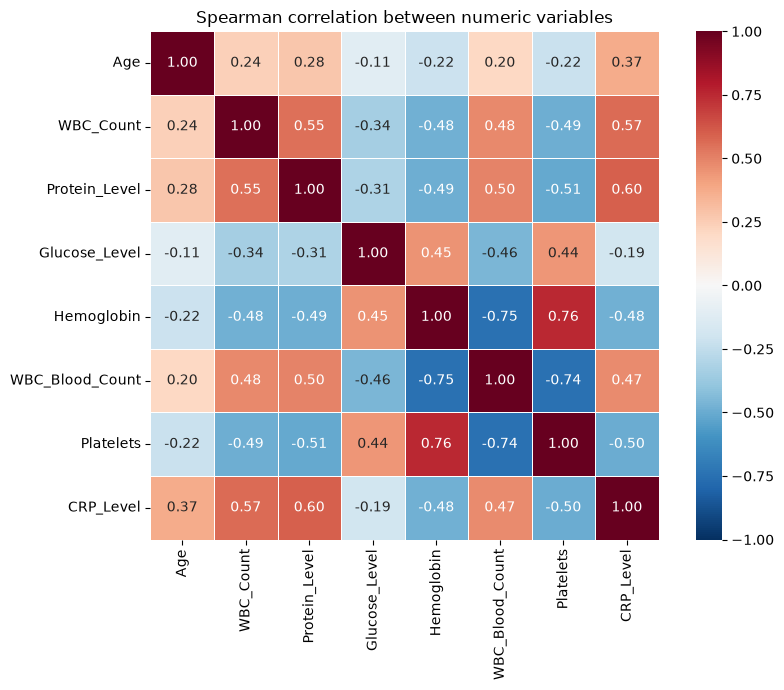

In [79]:
numerics = meningitis_clean[numeric_columns].astype(float)
corr = numerics.corr(method="spearman")

plt.figure(figsize=(9, 7))
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", square=True, linewidths=0.5)
plt.title("Spearman correlation between numeric variables")
plt.tight_layout()
plt.show()

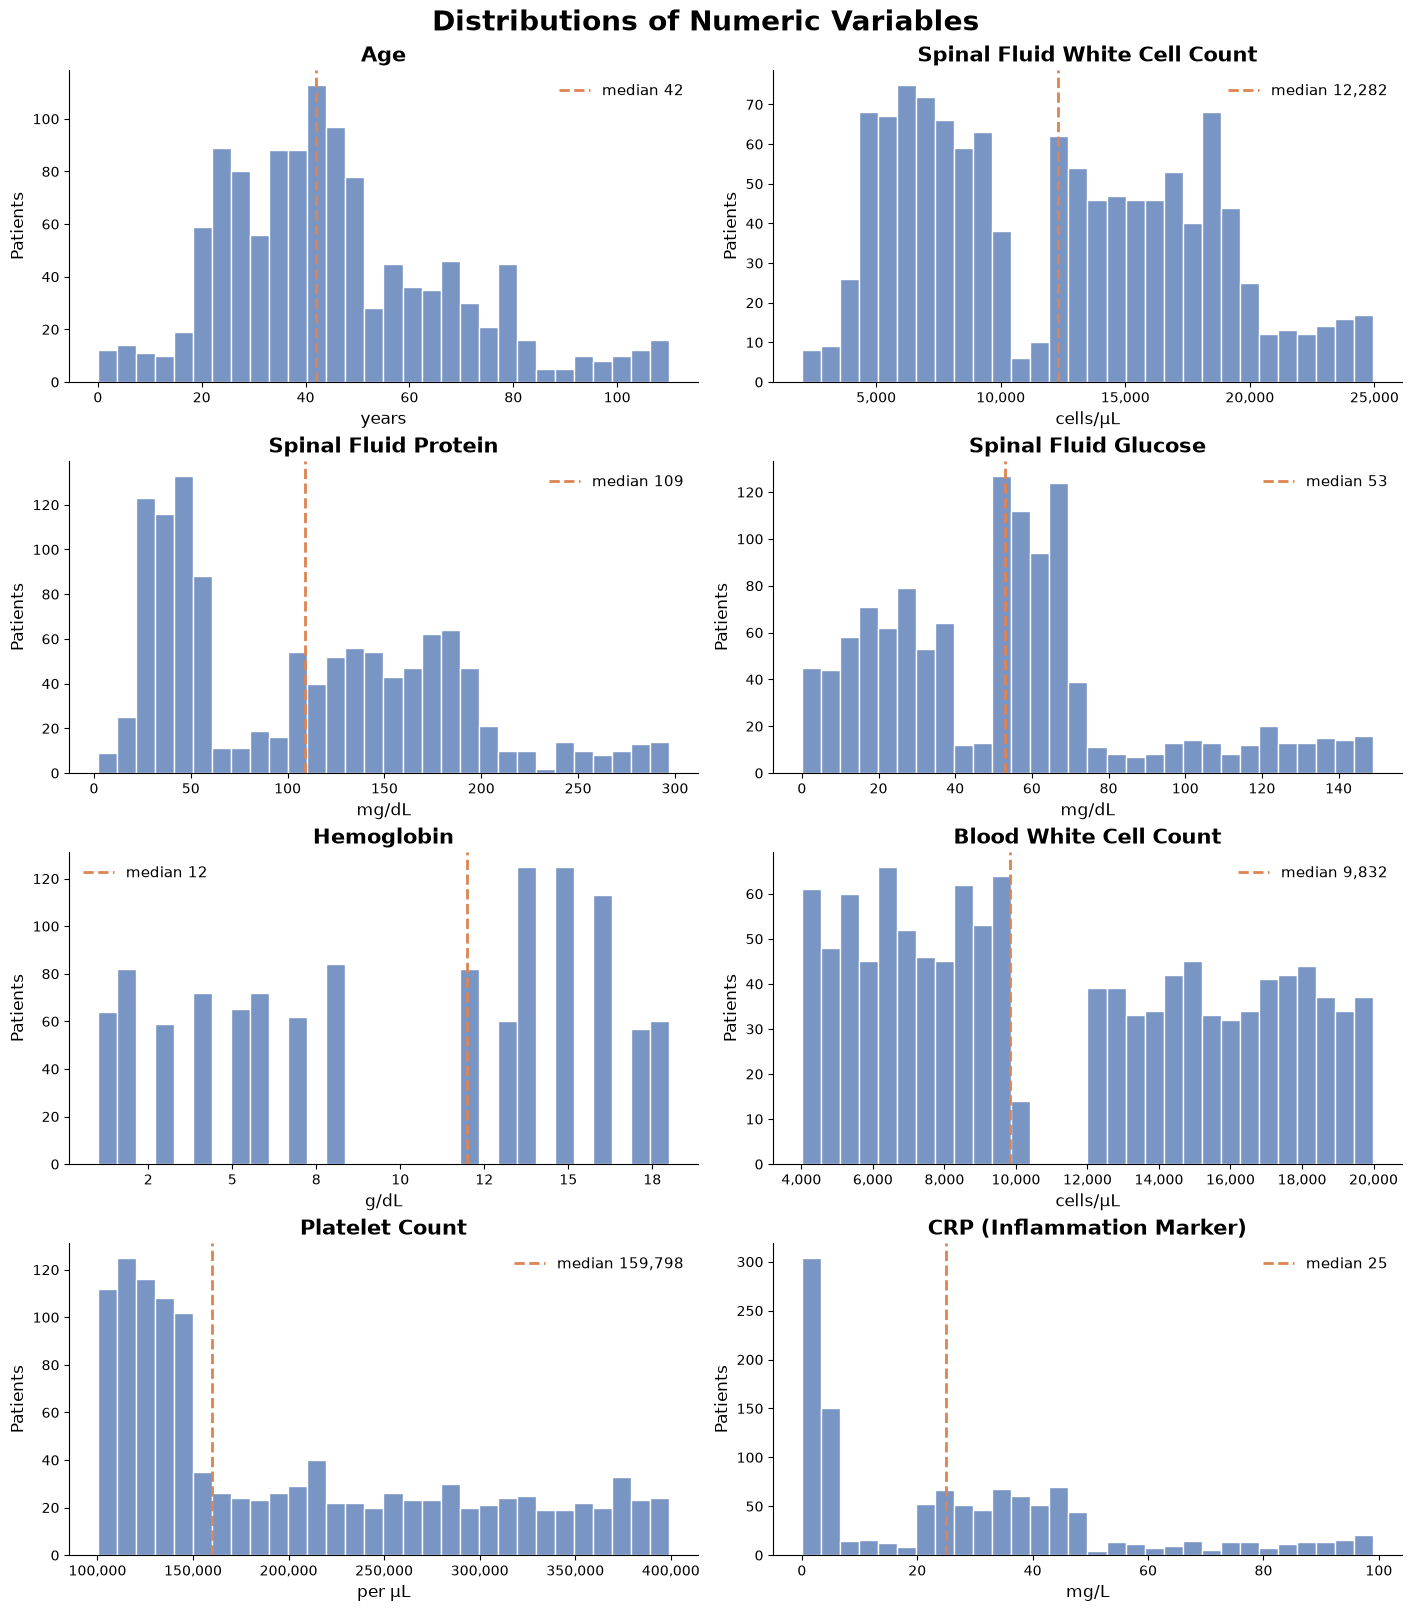

In [155]:
from matplotlib.ticker import FuncFormatter

labels = {
    "Age":             ("Age", "years"),
    "WBC_Count":       ("Spinal Fluid White Cell Count", "cells/µL"),
    "Protein_Level":   ("Spinal Fluid Protein", "mg/dL"),
    "Glucose_Level":   ("Spinal Fluid Glucose", "mg/dL"),
    "Hemoglobin":      ("Hemoglobin", "g/dL"),
    "WBC_Blood_Count": ("Blood White Cell Count", "cells/µL"),
    "Platelets":       ("Platelet Count", "per µL"),
    "CRP_Level":       ("CRP (Inflammation Marker)", "mg/L"),
}

numerics = meningitis_clean[numeric_columns].astype(float)
fig, axes = plt.subplots(4, 2, figsize=(14, 16), constrained_layout=True)

for col, ax in zip(numeric_columns, axes.flat):
    title, unit = labels[col]
    sns.histplot(numerics[col], bins=30, color="#4C72B0", edgecolor="white", ax=ax)
    median = numerics[col].median()
    ax.axvline(median, color="#DD8452", linewidth=2, linestyle="--",
               label=f"median {median:,.0f}")
    ax.set_title(title, fontsize=15, fontweight="bold")
    ax.set_xlabel(unit, fontsize=12)
    ax.set_ylabel("Patients", fontsize=12)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.legend(fontsize=11, frameon=False)
    sns.despine(ax=ax)

fig.suptitle("Distributions of Numeric Variables", fontsize=20, fontweight="bold")
plt.show()

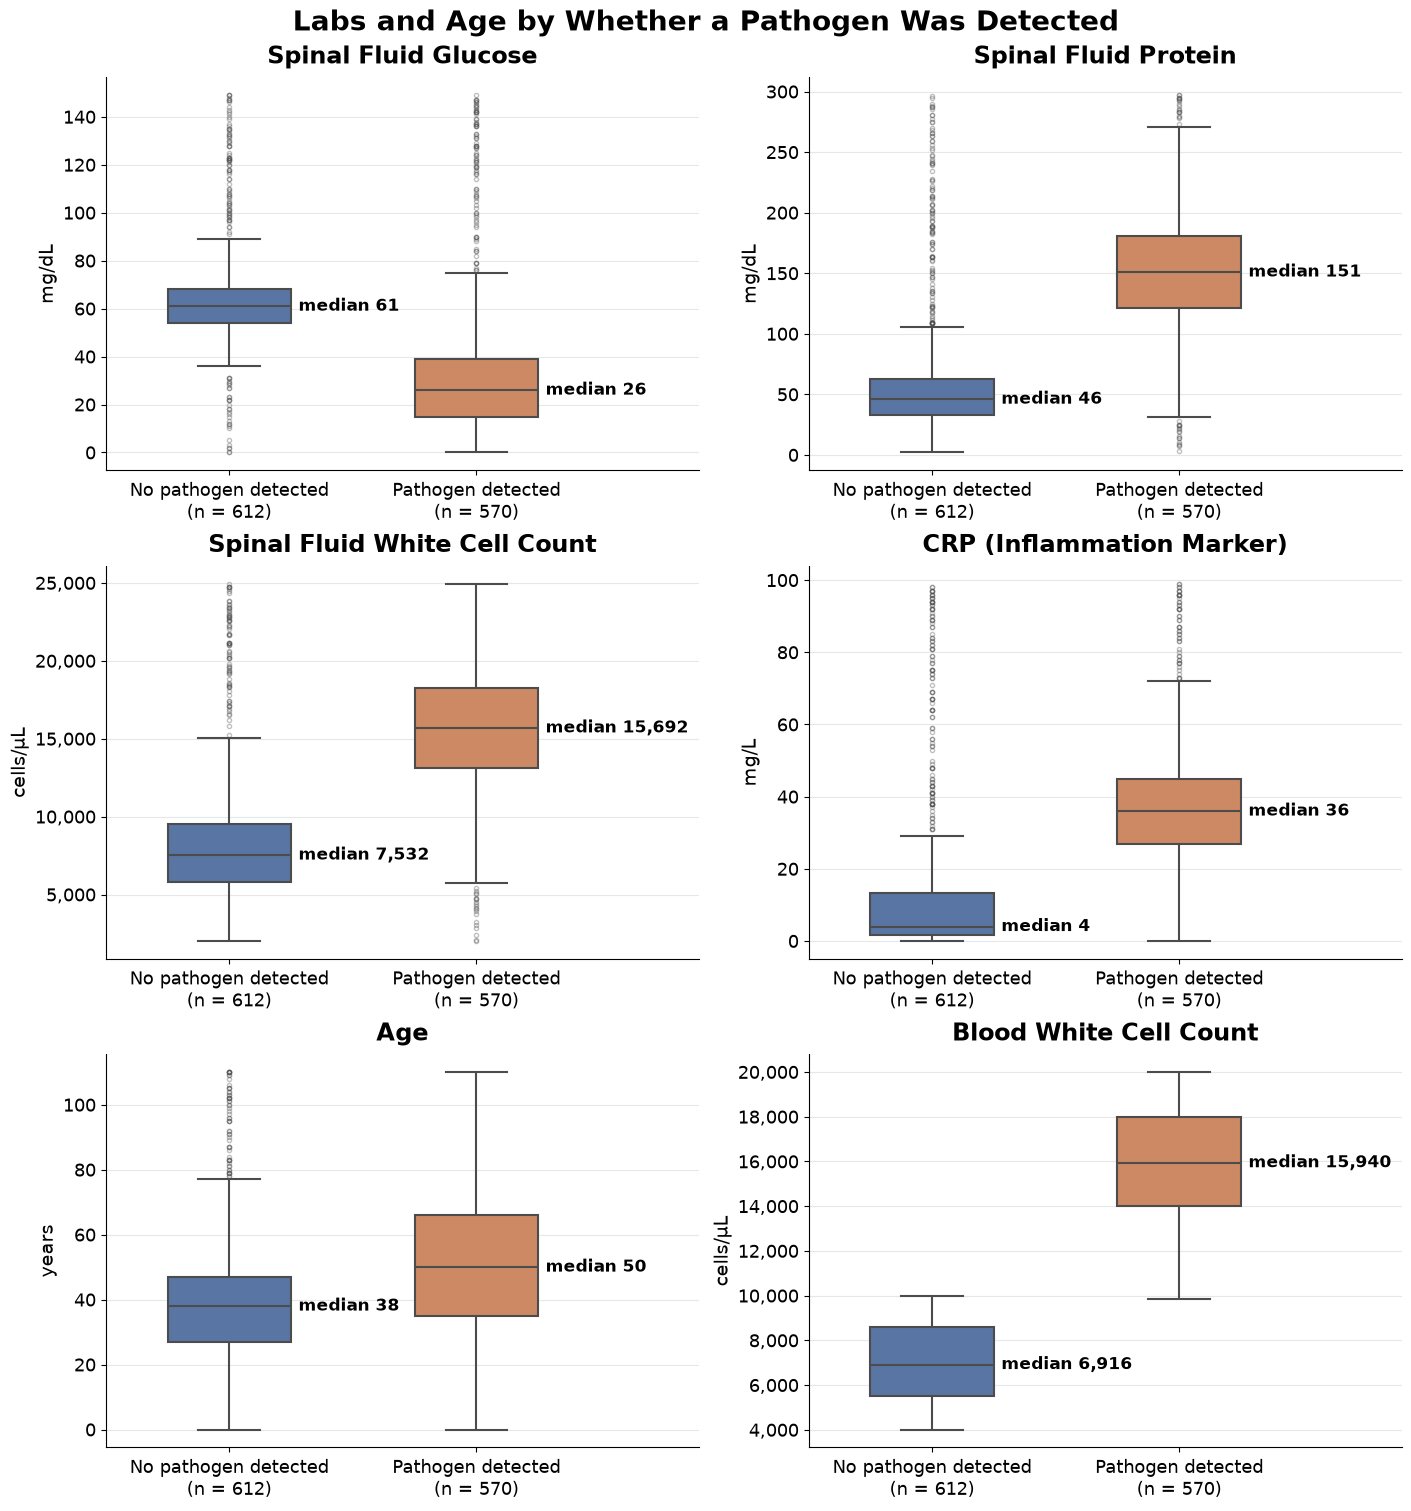

In [93]:
from matplotlib.ticker import FuncFormatter

plots = [
    ("Glucose_Level",   "Spinal Fluid Glucose",          "mg/dL"),
    ("Protein_Level",   "Spinal Fluid Protein",          "mg/dL"),
    ("WBC_Count",       "Spinal Fluid White Cell Count", "cells/µL"),
    ("CRP_Level",       "CRP (Inflammation Marker)",     "mg/L"),
    ("Age",             "Age",                           "years"),
    ("WBC_Blood_Count", "Blood White Cell Count",        "cells/µL"),
]
palette = {False: "#4C72B0", True: "#DD8452"}

# Group sizes for the x-axis labels
counts = meningitis_clean["Pathogen_Present"].value_counts()
x_labels = [f"No pathogen detected\n(n = {counts[False]:,})",
            f"Pathogen detected\n(n = {counts[True]:,})"]

fig, axes = plt.subplots(3, 2, figsize=(14, 15), constrained_layout=True)

for (col, title, unit), ax in zip(plots, axes.flat):
    sns.boxplot(data=meningitis_clean, x="Pathogen_Present", y=col, hue="Pathogen_Present",
                palette=palette, legend=False, width=0.5, linewidth=1.5,
                flierprops={"marker": "o", "markersize": 3, "alpha": 0.35}, ax=ax)

    medians = meningitis_clean.groupby("Pathogen_Present")[col].median()
    for i, m in enumerate(medians):
        ax.text(i + 0.28, m, f"median {m:,.0f}", va="center", fontsize=12, fontweight="bold")

    ax.set_title(title, fontsize=17, fontweight="bold", pad=10)
    ax.set_xlabel("")
    ax.set_ylabel(unit, fontsize=14)
    ax.set_xticks([0, 1], x_labels)
    ax.tick_params(axis="both", labelsize=13)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.grid(axis="y", alpha=0.3)
    ax.set_xlim(-0.5, 1.9)
    sns.despine(ax=ax)

fig.suptitle("Labs and Age by Whether a Pathogen Was Detected",
             fontsize=20, fontweight="bold")
plt.show()

In [97]:
deceased = meningitis_clean[meningitis_clean["Outcome"] == "Deceased"]
deceased.head(5)

,Age,WBC_Count,Protein_Level,Glucose_Level,Pathogen_Present,Outcome,Hemoglobin,WBC_Blood_Count,Platelets,CRP_Level,...,CRP_Level_Below_Detection,Age_imputed,Age_Group,Is_Minor,Gender_Female,Gender_Male,Gender_Unknown,Diagnosis_Bacterial,Diagnosis_Unknown,Diagnosis_Viral
10,42,9369,27,68,False,Deceased,14,7615.0,263696.0,4,...,False,True,Adult (25-64),False,False,True,False,False,False,True
21,0,21062,248,69,False,Deceased,18,5676.0,221767.0,8,...,False,False,Infant (<1),True,False,True,False,True,False,False
42,48,5111,59,53,False,Deceased,17,7194.0,324930.0,0,...,True,False,Adult (25-64),False,False,True,False,False,False,True
91,66,11719,211,57,True,Deceased,4,13100.0,103693.0,12,...,False,False,Older adult (65+),False,False,True,False,True,False,False
112,64,12224,133,20,True,Deceased,3,14416.0,143453.0,44,...,False,False,Adult (25-64),False,False,True,False,True,False,False


In [111]:
counts = deceased["Age_Group"].value_counts()

combined = pd.DataFrame({
    "Count": counts,
    "Percent of Deaths (%)": (counts / counts.sum() * 100).round(1),
})
combined

,Count,Percent of Deaths (%)
Age_Group,,
Adult (25-64),76,62.8
Older adult (65+),23,19.0
Young adult (18-24),16,13.2
Infant (<1),2,1.7
Adolescent (13-17),2,1.7
Young Child (1-4),1,0.8
Child (5-12),1,0.8


In [119]:
infections = meningitis_clean[meningitis_clean["Diagnosis_Unknown"] == False]

In [129]:
age_order = ["Infant (<1)", "Young Child (1-4)", "Child (5-12)", "Adolescent (13-17)",
             "Young adult (18-24)", "Adult (25-64)", "Older adult (65+)"]

# Counts of patients by age group and pathogen detection
pathogen_counts = infections.pivot_table(index="Age_Group", columns="Pathogen_Present",
                                         values="Age", aggfunc="count", fill_value=0)
pathogen_counts = pathogen_counts.rename(columns={False: "Not Detected", True: "Detected"})

# Percent within each age group (each row adds up to 100)
pathogen_pcts = (pathogen_counts.div(pathogen_counts.sum(axis=1), axis=0) * 100).round(1)

# Combine into one table with clear column names
pathogen_table = pd.DataFrame({
    "Total (n)":        pathogen_counts.sum(axis=1),
    "Pathogen Not Detected (n)": pathogen_counts["Not Detected"],
    "Pathogen Detected (n)":     pathogen_counts["Detected"],
    "Pathogen Not Detected (%)": pathogen_pcts["Not Detected"],
    "Pathogen Detected (%)":     pathogen_pcts["Detected"],
}).sort_values("Pathogen Detected (%)", ascending=False)

pathogen_table

,Total (n),Pathogen Not Detected (n),Pathogen Detected (n),Pathogen Not Detected (%),Pathogen Detected (%)
Age_Group,,,,,
Older adult (65+),186,49,137,26.3,73.7
Young Child (1-4),9,3,6,33.3,66.7
Adolescent (13-17),6,2,4,33.3,66.7
Child (5-12),20,8,12,40.0,60.0
Adult (25-64),688,390,298,56.7,43.3
Young adult (18-24),133,92,41,69.2,30.8
Infant (<1),4,3,1,75.0,25.0


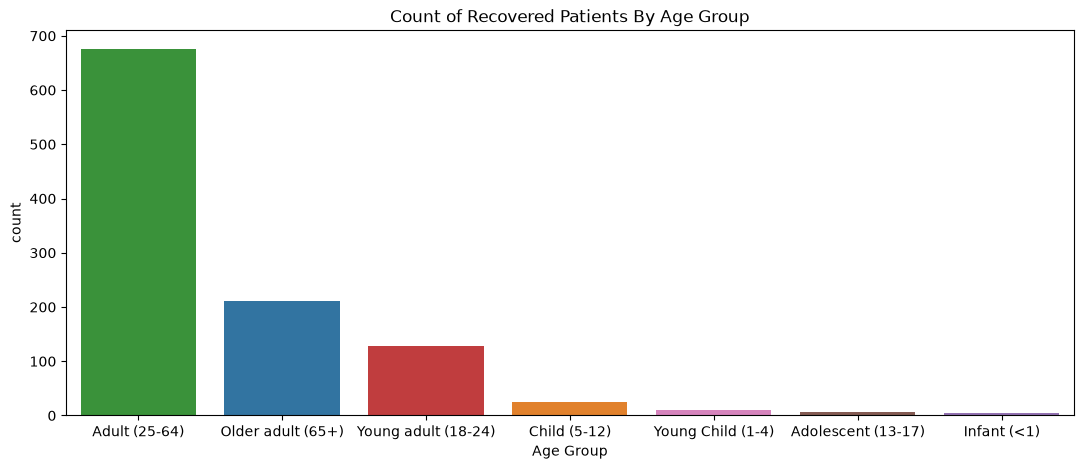

In [141]:
plt.figure(figsize=(13, 5))
recovered = meningitis_clean[meningitis_clean["Outcome"] == "Recovered"]
order1 = recovered["Age_Group"].value_counts().index
sns.countplot(data=recovered, x="Age_Group", order=order1, hue="Age_Group")
plt.title("Count of Recovered Patients By Age Group")
plt.xlabel("Age Group")
plt.show()

In [143]:
meningitis_clean

,Age,WBC_Count,Protein_Level,Glucose_Level,Pathogen_Present,Outcome,Hemoglobin,WBC_Blood_Count,Platelets,CRP_Level,...,CRP_Level_Below_Detection,Age_imputed,Age_Group,Is_Minor,Gender_Female,Gender_Male,Gender_Unknown,Diagnosis_Bacterial,Diagnosis_Unknown,Diagnosis_Viral
0,101,8624,16,83,False,Recovered,15,7269.0,160949.0,71,...,False,False,Older adult (65+),False,True,False,False,False,False,True
1,78,22623,200,41,False,Recovered,18,6532.0,371741.0,41,...,False,False,Older adult (65+),False,False,True,False,False,True,False
2,8,12908,39,3,False,Recovered,16,7417.0,180403.0,22,...,False,False,Child (5-12),True,True,False,False,False,True,False
3,104,15072,58,36,True,Recovered,7,13792.0,132254.0,48,...,False,False,Older adult (65+),False,True,False,False,True,False,False
4,38,18623,152,34,True,Recovered,5,17054.0,134941.0,28,...,False,False,Adult (25-64),False,True,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1195,64,13772,163,118,False,Recovered,16,9267.0,183229.0,29,...,False,False,Adult (25-64),False,False,True,False,False,True,False
1196,79,17393,117,2,False,Recovered,18,6952.0,291451.0,23,...,False,False,Older adult (65+),False,False,True,False,False,True,False
1197,25,8005,23,69,False,Recovered,13,7389.0,275364.0,4,...,False,False,Adult (25-64),False,True,False,False,False,False,True
1198,73,13581,161,29,True,Recovered,7,19034.0,102130.0,35,...,False,False,Older adult (65+),False,False,True,False,True,False,False


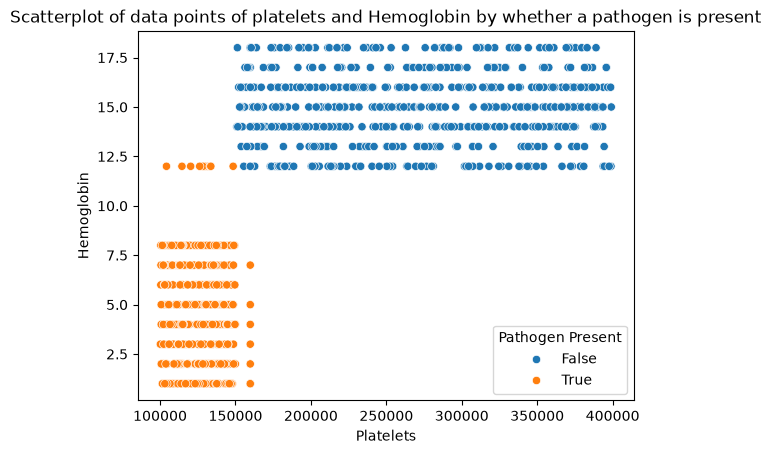

In [150]:
sns.scatterplot(data=meningitis_clean, x="Platelets", y="Hemoglobin", hue="Pathogen_Present")
plt.title("Scatterplot of data points of platelets and Hemoglobin by whether a pathogen is present")
plt.legend(title="Pathogen Present")
plt.show()

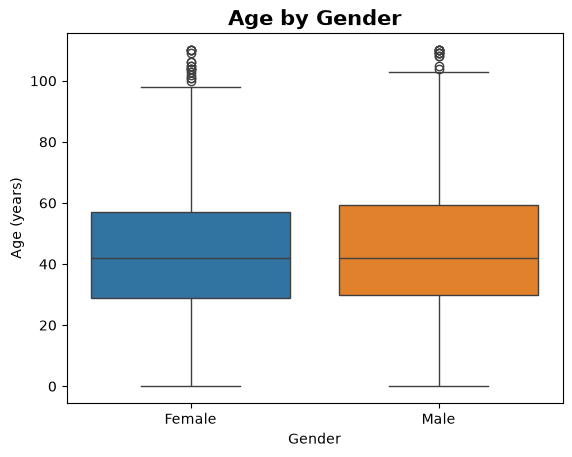

In [162]:
gender_cols= ["Gender_Female", "Gender_Male", "Gender_Unknown"]

meningitis_clean["Gender"] = (meningitis_clean[gender_cols].astype(int)
                              .idxmax(axis=1).str.replace("Gender_", "", regex=False))

known_gender = meningitis_clean[meningitis_clean["Gender"] != "Unknown"]
ax = sns.boxplot(data=known_gender, x="Gender", y="Age", hue="Gender",
                 order=["Female", "Male"], legend=False)
ax.set_title("Age by Gender", fontsize=15, fontweight="bold")
ax.set_xlabel("Gender")
ax.set_ylabel("Age (years)")
plt.show()

In [168]:
pathogen_counts = known_gender.pivot_table(index="Gender", columns="Pathogen_Present", values="Age", aggfunc="count")

pathogen_counts = pathogen_counts.rename(columns={False: "Not Detected", True: "Detected"})

# Percent within each age group (each row adds up to 100)
pathogen_pcts = (pathogen_counts.div(pathogen_counts.sum(axis=1), axis=0) * 100).round(1)

# Combine into one table with clear column names
pathogen_table = pd.DataFrame({
    "Total (n)":        pathogen_counts.sum(axis=1),
    "Pathogen Not Detected (n)": pathogen_counts["Not Detected"],
    "Pathogen Detected (n)":     pathogen_counts["Detected"],
    "Pathogen Not Detected (%)": pathogen_pcts["Not Detected"],
    "Pathogen Detected (%)":     pathogen_pcts["Detected"],
}).sort_values("Pathogen Detected (%)", ascending=False)

pathogen_table

,Total (n),Pathogen Not Detected (n),Pathogen Detected (n),Pathogen Not Detected (%),Pathogen Detected (%)
Gender,,,,,
Male,595,307,288,51.6,48.4
Female,578,301,277,52.1,47.9


**Build a Classification Pipeline** – How accurately can I predict whether a pathogen was present?

In [55]:
meningitis_clean["Pathogen_Present"].value_counts()

Pathogen_Present
False    612
True     570
Name: count, dtype: int64

In [57]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, cross_validate, GridSearchCV, cross_val_predict
from sklearn.metrics import classification_report, roc_auc_score 
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.calibration import CalibratedClassifierCV
from xgboost import XGBClassifier

**Define input variables and target**

In [58]:
pathogen_features = [
    "Glucose_Level", "CRP_Level", "WBC_Count", "Protein_Level",  # spinal fluid + CRP
    "Age", "Gender_Female", "Gender_Unknown",
]
pathogen_target = "Pathogen_Present"

X = meningitis_clean[pathogen_features].astype("float64")
Y = meningitis_clean[pathogen_target].astype(int)  

In [59]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.20, stratify=Y, random_state=42
)

In [60]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

**Try Other Models: Do They Perform Better? **
- Logistic Regression 
- Decision Tree
- KNN Classification 
- SVM (RBF)
- Random Forest
- Gradient Boosting

In [61]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=42),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
    "SVM (RBF)": make_pipeline(StandardScaler(),
                           CalibratedClassifierCV(SVC(random_state=42), ensemble=False)),
    "Random Forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=3, random_state=42, n_jobs=-1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=42),
    "XGBoost":             XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                                         subsample=0.8, colsample_bytree=0.8,
                                         eval_metric="logloss", random_state=42, n_jobs=-1),
}

In [62]:
rows = []
for name, model in models.items():
    r = cross_validate(model, X_train, Y_train, cv=cv,
                       scoring=["roc_auc", "accuracy", "recall", "precision"])
    rows.append({"model": name,
                 "roc_auc": r["test_roc_auc"].mean(), "roc_auc_sd": r["test_roc_auc"].std(),
                 "accuracy": r["test_accuracy"].mean(),
                 "recall_detected": r["test_recall"].mean(),
                 "precision_detected": r["test_precision"].mean()})

results = pd.DataFrame(rows).sort_values("roc_auc", ascending=False).round(3)
print(results.to_string(index=False))

                 model  roc_auc  roc_auc_sd  accuracy  recall_detected  precision_detected
         Random Forest    0.956       0.011     0.860            0.846               0.863
Hist Gradient Boosting    0.953       0.009     0.865            0.862               0.860
               XGBoost    0.950       0.012     0.851            0.855               0.841
                   KNN    0.949       0.010     0.856            0.897               0.823
             SVM (RBF)    0.942       0.015     0.843            0.842               0.836
         Decision Tree    0.936       0.018     0.843            0.800               0.874
   Logistic Regression    0.887       0.019     0.847            0.857               0.830


#### Model Results

- Using the ROC-AUC score on the test set as the north star, the random forest model performs the best on this set of data

| Model               | ROC AUC | ROC AUC SD | Accuracy | Recall | Precision |
|---------------------|:-------:|:----------:|:--------:|:------:|:---------:|
| Random Forest       | **0.956** | 0.011    | 0.860    | 0.846  | 0.863     |
| Gradient Boosting   | 0.953   | 0.009      | **0.865** | 0.862 | 0.860     |
| KNN                 | 0.949   | 0.010      | 0.856    | **0.897** | 0.823  |
| SVM (RBF)           | 0.942   | 0.015      | 0.843    | 0.842  | 0.836     |
| Decision Tree       | 0.936   | 0.018      | 0.843    | 0.800  | **0.874** |
| Logistic Regression | 0.887   | 0.019      | 0.847    | 0.857  | 0.830     |

**Can the Random Forest Model ROC-AUC be improved upon**
- hyperparameterize the min sample leaef and max depth arguments in the model
- THe base model actually performs better as compared to the optimized model
- We can confidently state that the basea random forest classifier model performs the best, returning a ROC-AUC score of 0.956

In [63]:
grid = GridSearchCV(
    RandomForestClassifier(n_estimators=500, random_state=42, n_jobs=-1),
    param_grid={"min_samples_leaf": [3, 5, 10, 20, 30],
                "max_depth": [None, 8, 12]},
    cv=cv, scoring="roc_auc", n_jobs=-1)
grid.fit(X_train, Y_train)
print("Best params:", grid.best_params_, "| CV ROC-AUC:", round(grid.best_score_, 3))
best_rf = grid.best_estimator_


Best params: {'max_depth': None, 'min_samples_leaf': 10} | CV ROC-AUC: 0.96


In [64]:
cv_probs = cross_val_predict(best_rf, X_train, Y_train, cv=cv, method="predict_proba")[:, 1]

In [65]:
from sklearn.metrics import recall_score, precision_score, accuracy_score

y_true = Y_train.astype(int)   # works whether Y_train is bool or int

for t in [0.5, 0.45, 0.4, 0.35, 0.3]:
    p = (cv_probs >= t).astype(int)
    print(f"threshold {t:.2f}: recall {recall_score(y_true, p):.3f}, "
          f"precision {precision_score(y_true, p):.3f}, "
          f"accuracy {accuracy_score(y_true, p):.3f}")

THRESHOLD = 0.4   # set this from the table above, based on your recall goal

threshold 0.50: recall 0.851, precision 0.858, accuracy 0.860
threshold 0.45: recall 0.917, precision 0.826, accuracy 0.867
threshold 0.40: recall 0.967, precision 0.796, accuracy 0.865
threshold 0.35: recall 0.980, precision 0.773, accuracy 0.852
threshold 0.30: recall 0.993, precision 0.763, accuracy 0.848


In [66]:
test_probs = best_rf.predict_proba(X_test)[:, 1]
test_preds = (test_probs >= THRESHOLD).astype(int)

print(f"\nTest ROC-AUC: {roc_auc_score(Y_test, test_probs):.3f}\n")
print(classification_report(Y_test, test_preds, target_names=["Not detected", "Detected"]))
print(pd.DataFrame(confusion_matrix(Y_test, test_preds),
                   index=["True: Not detected", "True: Detected"],
                   columns=["Pred: Not detected", "Pred: Detected"]))


Test ROC-AUC: 0.945

              precision    recall  f1-score   support

Not detected       0.95      0.76      0.84       123
    Detected       0.78      0.96      0.86       114

    accuracy                           0.85       237
   macro avg       0.87      0.86      0.85       237
weighted avg       0.87      0.85      0.85       237

                    Pred: Not detected  Pred: Detected
True: Not detected                  93              30
True: Detected                       5             109


In [67]:
print(pd.Series(best_rf.feature_importances_, index=pathogen_features)
        .sort_values(ascending=False).round(3))

Glucose_Level     0.318
CRP_Level         0.273
WBC_Count         0.202
Protein_Level     0.147
Age               0.057
Gender_Female     0.002
Gender_Unknown    0.000
dtype: float64


**Perform Classification Model to Predict Whether a Case is a Bacterial or Viral**

In [68]:
infections = meningitis_clean[meningitis_clean["Diagnosis_Unknown"] == False]

In [69]:
infections["Diagnosis_Bacterial"].value_counts()

Diagnosis_Bacterial
False    554
True     492
Name: count, dtype: int64

In [70]:
diag_features = ["Glucose_Level", "CRP_Level", "WBC_Count", "Protein_Level",
                 "Age", "Gender_Female", "Gender_Unknown"]
X = infections[diag_features].astype("float64")
Y = infections["Diagnosis_Bacterial"].astype(int)     # 1 = bacterial, 0 = viral

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.20, stratify=Y, random_state=42)

In [71]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.20, stratify=Y, random_state=42
)

In [72]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
    "Decision Tree":       DecisionTreeClassifier(max_depth=4, random_state=42),
    "KNN":                 make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
    "SVM (RBF)":           make_pipeline(StandardScaler(), SVC(random_state=42)),
    "Random Forest":       RandomForestClassifier(n_estimators=500, min_samples_leaf=20,
                                                  random_state=42, n_jobs=-1),
    "Hist Gradient Boosting":   HistGradientBoostingClassifier(random_state=42),
    "XGBoost":             XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                                         subsample=0.8, colsample_bytree=0.8,
                                         eval_metric="logloss", random_state=42, n_jobs=-1),
}

In [73]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["roc_auc", "accuracy", "recall", "precision"]

rows = []
for name, model in models.items():
    r = cross_validate(model, X_train, Y_train, cv=cv, scoring=scoring)
    rows.append({
        "model": name,
        "roc_auc": r["test_roc_auc"].mean(),
        "roc_auc_sd": r["test_roc_auc"].std(),
        "accuracy": r["test_accuracy"].mean(),
        "recall_bacterial": r["test_recall"].mean(),
        "precision_bacterial": r["test_precision"].mean()
    })

results = pd.DataFrame(rows).sort_values("roc_auc", ascending=False).round(3)
print(results.to_string(index=False))

                 model  roc_auc  roc_auc_sd  accuracy  recall_bacterial  precision_bacterial
               XGBoost    0.975       0.010     0.890             0.880                0.888
Hist Gradient Boosting    0.973       0.012     0.896             0.903                0.881
         Random Forest    0.972       0.012     0.889             0.891                0.879
             SVM (RBF)    0.970       0.013     0.886             0.873                0.887
                   KNN    0.966       0.015     0.894             0.929                0.861
         Decision Tree    0.929       0.034     0.878             0.830                0.907
   Logistic Regression    0.919       0.037     0.890             0.903                0.871


In [74]:
xgb = models["XGBoost"]

# Cross-validated predictions on the training set (each row predicted by a model that didn't see it)
cv_probs = cross_val_predict(xgb, X_train, Y_train, cv=cv, method="predict_proba")[:, 1]
cv_preds = (cv_probs >= 0.5).astype(int)

print(f"CV ROC-AUC: {roc_auc_score(Y_train, cv_probs):.3f}\n")
print(classification_report(Y_train, cv_preds, target_names=["Viral", "Bacterial"]))
print(pd.DataFrame(confusion_matrix(Y_train, cv_preds),
                   index=["True: Viral", "True: Bacterial"],
                   columns=["Pred: Viral", "Pred: Bacterial"]))

CV ROC-AUC: 0.975

              precision    recall  f1-score   support

       Viral       0.89      0.90      0.90       443
   Bacterial       0.88      0.88      0.88       393

    accuracy                           0.89       836
   macro avg       0.89      0.89      0.89       836
weighted avg       0.89      0.89      0.89       836

                 Pred: Viral  Pred: Bacterial
True: Viral              398               45
True: Bacterial           47              346


**Hyperparameterize the XGBoost Machine Learning Model**

In [75]:
from sklearn.model_selection import RandomizedSearchCV, cross_val_predict
from sklearn.metrics import (roc_auc_score, classification_report, confusion_matrix,
                             recall_score, precision_score, accuracy_score)
from scipy.stats import uniform, randint

In [76]:
search = RandomizedSearchCV(
    XGBClassifier(eval_metric="logloss", random_state=42, n_jobs=-1),
    param_distributions={
        "n_estimators":     randint(200, 1000),
        "learning_rate":    uniform(0.01, 0.09),    # 0.01 to 0.10
        "max_depth":        randint(2, 7),
        "min_child_weight": randint(1, 10),
        "subsample":        uniform(0.6, 0.4),      # 0.6 to 1.0
        "colsample_bytree": uniform(0.6, 0.4),
        "reg_lambda":       uniform(0.5, 5),
    },
    n_iter=50, cv=cv, scoring="roc_auc", random_state=42, n_jobs=-1, return_train_score=True,   
)
search.fit(X_train, Y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': <scipy.stats....002010005D250>, 'learning_rate': <scipy.stats....002017E85C9B0>, 'max_depth': <scipy.stats....002017E7D0170>, 'min_child_weight': <scipy.stats....002010005D9D0>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",50
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric eva

In [77]:
print("Best params:", search.best_params_)
print(f"Best CV ROC-AUC: {search.best_score_:.3f}")

Best params: {'colsample_bytree': np.float64(0.7470863212237734), 'learning_rate': np.float64(0.03386821309135529), 'max_depth': 6, 'min_child_weight': 3, 'n_estimators': 637, 'reg_lambda': np.float64(5.03049393859277), 'subsample': np.float64(0.7737577462041715)}
Best CV ROC-AUC: 0.975


In [78]:
best_xgb = search.best_estimator_

In [79]:
cv_probs = cross_val_predict(best_xgb, X_train, Y_train, cv=cv, method="predict_proba")[:, 1]

for t in [0.5, 0.45, 0.4, 0.35, 0.3, 0.25]:
    p = (cv_probs >= t).astype(int)
    print(f"threshold {t:.2f}: bacterial recall {recall_score(Y_train, p):.3f}, "
          f"precision {precision_score(Y_train, p):.3f}, accuracy {accuracy_score(Y_train, p):.3f}")

THRESHOLD = 0.35   # pick from the table above, e.g. the highest cutoff giving recall >= 0.95

threshold 0.50: bacterial recall 0.888, precision 0.886, accuracy 0.894
threshold 0.45: bacterial recall 0.906, precision 0.875, accuracy 0.895
threshold 0.40: bacterial recall 0.924, precision 0.864, accuracy 0.896
threshold 0.35: bacterial recall 0.936, precision 0.852, accuracy 0.894
threshold 0.30: bacterial recall 0.944, precision 0.841, accuracy 0.890
threshold 0.25: bacterial recall 0.949, precision 0.829, accuracy 0.884


In [80]:
# ---------- 4. Final evaluation on the test set (once) ----------
test_probs = best_xgb.predict_proba(X_test)[:, 1]
test_preds = (test_probs >= THRESHOLD).astype(int)

print(f"\nTest ROC-AUC: {roc_auc_score(Y_test, test_probs):.3f}\n")
print(classification_report(Y_test, test_preds, target_names=["Viral", "Bacterial"]))
print(pd.DataFrame(confusion_matrix(Y_test, test_preds),
                   index=["True: Viral", "True: Bacterial"],
                   columns=["Pred: Viral", "Pred: Bacterial"]))



Test ROC-AUC: 0.980

              precision    recall  f1-score   support

       Viral       0.94      0.88      0.91       111
   Bacterial       0.88      0.94      0.91        99

    accuracy                           0.91       210
   macro avg       0.91      0.91      0.91       210
weighted avg       0.91      0.91      0.91       210

                 Pred: Viral  Pred: Bacterial
True: Viral               98               13
True: Bacterial            6               93


In [81]:
print(pd.Series(best_xgb.feature_importances_, index=diag_features)
        .sort_values(ascending=False).round(3))

CRP_Level         0.323
WBC_Count         0.224
Glucose_Level     0.216
Protein_Level     0.137
Age               0.061
Gender_Female     0.038
Gender_Unknown    0.000
dtype: float32
